In [3]:
!pip install line_profiler

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 750.2/750.2 kB 15.3 MB/s eta 0:00:00


In [4]:
%load_ext line_profiler

In [5]:
import sympy as sp
import numpy as np
import sys
import matplotlib.pyplot as plt
import pandas as pd
from numba import jit
import time

Рассмотрим приближение для $\theta$ из уравнения $\theta = arctan(y/x)$\
Подставим x,y в выражение для $arctan$;

Разделим уравнение для теты на две функции:

$$f(\theta) = \theta$$

$$и$$

$$f(\theta) = arctan(\frac{5 \cdot \sin(\theta) \cdot t - 0.5 \cdot 9.8 \cdot t^2 + 0.1 \cdot t}{5 \cdot \cos(\theta) \cdot t})$$

Т.к. самолетик летит по парабаллической траектории (-t^2), то в точке достжения вершины y' = 0. Из этого уравнения выразим t:
$$t = \frac{(5 \cdot \sin(\theta) + 0.1)}{9.8}$$

Построим графики f и посмотрим их точки пересечения. В точках пересечения равенство для $\theta$ выполняется.

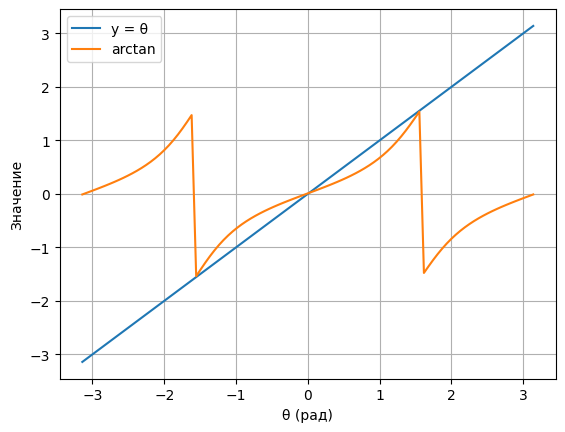

In [25]:
theta_range = np.linspace(-np.pi, np.pi, 100)  # Диапазон углов
left = theta_range  # Левая часть: y = θ
right = []

for theta in theta_range:
    t = (5 * np.sin(theta) + 0.1) / 9.8
    numerator = 5 * np.sin(theta) * t - 0.5 * 9.8 * t**2 + 0.1 * t
    denominator = 5 * np.cos(theta) * t
    right.append(np.arctan(numerator / denominator) if denominator != 0 else 0)

plt.plot(theta_range, left, label="y = θ")
plt.plot(theta_range, right, label="arctan")
plt.xlabel("θ (рад)")
plt.ylabel("Значение")
plt.legend()
plt.grid()
plt.show()

Рассмотрим график поближе, в $\theta$ $[-0.5;\frac{π}{2} + 0.5]$

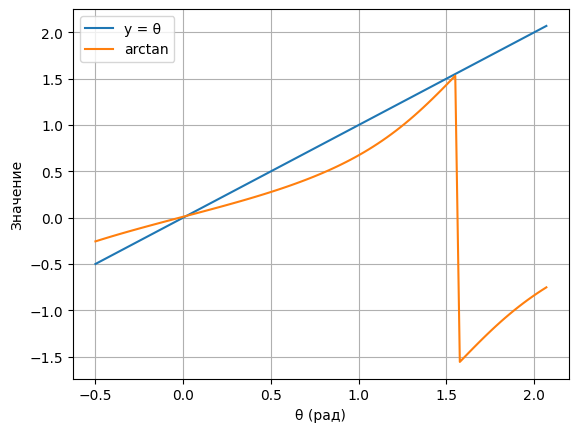

In [19]:
theta_range = np.linspace(-0.5, np.pi/2 + 0.5, 100)  # Диапазон углов
left = theta_range  # Левая часть: y = θ
right = []

for theta in theta_range:
    t = (5 * np.sin(theta) + 0.1) / 9.8
    numerator = 5 * np.sin(theta) * t - 0.5 * 9.8 * t**2 + 0.1 * t
    denominator = 5 * np.cos(theta) * t
    right.append(np.arctan(numerator / denominator) if denominator != 0 else 0)

plt.plot(theta_range, left, label="y = θ")
plt.plot(theta_range, right, label="arctan")
plt.xlabel("θ (рад)")
plt.ylabel("Значение")
plt.legend()
plt.grid()
plt.show()

Заметим, что корень скорее всего будет ~0 и/или $\frac{π}{2}$


In [27]:
print(f'при theta = 0: {(5 * np.sin(0) + 0.1) / 9.8}')
print(f'при theta = pi/2: {(5 * np.sin(np.pi/2) + 0.1) / 9.8}')

при theta = 0: 0.01020408163265306
при theta = pi/2: 0.520408163265306


$\frac{\pi}{2}$ является крайним случаем, при нем самолетик летит ровно вверх.

In [2]:
#@jit(nopython=True)
def simple_iterations(th_first, t_first, delta, b, dtype = np.float64):
    max_iter = 1000
    b = dtype(b)
    th_old, t_old = dtype(th_first), dtype(t_first)
    iters = 0

    for _ in range(max_iter):

        x = dtype(5 * dtype(np.cos(th_old)) * t_old)
        y = dtype(5 * dtype(np.sin(th_old)) * t_old - 0.5*9.8*t_old**2 + 0.1*t_old)

        if x == 0:
            th_new = dtype(th_old)
        else:
            th_new = dtype(th_old + b * (dtype(np.arctan(y/x)) - th_old))

        t_new = dtype(t_old + b * (dtype((5 * dtype(np.sin(th_old)) + 0.1)/9.8) - t_old))

        if (abs(th_new - th_old) < delta) and (abs(t_new - t_old) < delta):
            break
        th_old, t_old = dtype(th_new), dtype(t_new)
        iters += 1

    return th_new, t_new, iters

@jit(nopython=True)
def simple_iterations_fast(th_first, t_first, delta, b, dtype = np.float64):
    max_iter = 1000
    b = dtype(b)
    th_old, t_old = dtype(th_first), dtype(t_first)
    iters = 0

    for _ in range(max_iter):

        x = dtype(5 * dtype(np.cos(th_old)) * t_old)
        y = dtype(5 * dtype(np.sin(th_old)) * t_old - 0.5*9.8*t_old**2 + 0.1*t_old)

        if x == 0:
            th_new = dtype(th_old)
        else:
            th_new = dtype(th_old + b * (dtype(np.arctan(y/x)) - th_old))

        t_new = dtype(t_old + b * (dtype((5 * dtype(np.sin(th_old)) + 0.1)/9.8) - t_old))

        if (abs(th_new - th_old) < delta) and (abs(t_new - t_old) < delta):
            break
        th_old, t_old = dtype(th_new), dtype(t_new)
        iters += 1

    return th_new, t_new, iters

b_range = np.linspace(0.1,0.9,9)
dtypes  = [np.float32,np.float64]
deltas  = [0.01, 0.001, 0.0001]

table = []

for b in b_range:
  for delta in deltas:
    time_start = time.time()
    theta, t, iters = simple_iterations(0, 0.01, delta, b, dtype=np.float16)
    time_end = time.time()
    x = 5 * np.cos(theta) * t
    y = 5 * np.sin(theta) * t - 0.5*9.8 * t**2 + 0.1 * t
    abs_error_theta = abs(3/200 - theta)
    abs_error_t = abs(51/2500 - t)
    table.append([theta,t,x,y,iters,b,np.float16,delta,time_end-time_start,abs_error_theta,abs_error_t])

for dtype in dtypes:
  for b in b_range:
    for delta in deltas:
      time_start = time.time()
      theta, t, iters = simple_iterations_fast(0, 0.01, delta, b, dtype=dtype)
      time_end = time.time()
      x = 5 * np.cos(theta) * t
      y = 5 * np.sin(theta) * t - 0.5*9.8 * t**2 + 0.1 * t
      abs_error_theta = abs(3/200 - theta)
      abs_error_t = abs(51/2500 - t)
      table.append([theta,t,x,y,iters,b,dtype,delta,time_end-time_start,abs_error_theta,abs_error_t])
p = pd.DataFrame(table)
p.columns = 'theta,t,x,y,iters,b,dtype,delta,time spent,absolut error theta,absolute error t'.split(',')
pd.set_option('display.max_rows', None)  # Показывать все строки
display(p)

,theta,t,x,y,iters,b,dtype,delta,time spent,absolut error theta,absolute error t
0,0.001019,0.010025,0.050125,0.000561,0,0.1,<class 'numpy.float16'>,0.0100,0.000168,0.013981,0.010375
1,0.004047,0.010361,0.051804,0.000720,3,0.1,<class 'numpy.float16'>,0.0010,0.009743,0.010953,0.010039
2,0.021545,0.020386,0.101929,0.002198,43,0.1,<class 'numpy.float16'>,0.0001,0.008118,0.006545,0.000014
3,0.002039,0.010040,0.050201,0.000612,0,0.2,<class 'numpy.float16'>,0.0100,0.000079,0.012961,0.010360
4,0.017807,0.016037,0.080185,0.001771,10,0.2,<class 'numpy.float16'>,0.0010,0.001634,0.002807,0.004363
5,0.021561,0.020905,0.104523,0.002203,24,0.2,<class 'numpy.float16'>,0.0001,0.002546,0.006561,0.000505
6,0.003061,0.010063,0.050316,0.000664,0,0.3,<class 'numpy.float16'>,0.0100,0.000033,0.011939,0.010337
7,0.020889,0.018570,0.092850,0.002107,9,0.3,<class 'numpy.float16'>,0.0010,0.000349,0.005889,0.001830
8,0.019958,0.020599,0.102997,0.002036,26,0.3,<class 'numpy.float16'>,0.0001,0.002234,0.004958,0.000199
9,0.004078,0.010078,0.050392,0.000716,0,0.4,<class 'numpy.float16'>,0.0100,0.000050,0.010922,0.010322


Анализ скорости:

In [12]:
%lprun -f simple_iterations simple_iterations(0, 0.01, 0.001, 0.5, dtype=np.float64)

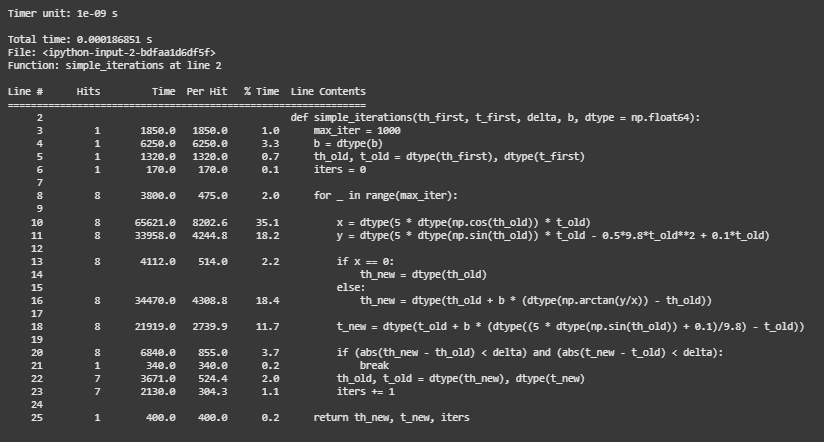

Основное количество времени тратится на вычисления новых значений t, theta, что свойственно методу простых итераций.

Используя njit функцию можно значительно оптимизировать - вычисления на более низкоуровневом языке будут проходить значительно быстрее.

Для float32 и float64 проведем оптимизацию: добавим njit и назовем функцию simple_iterations_fast.

траектория:

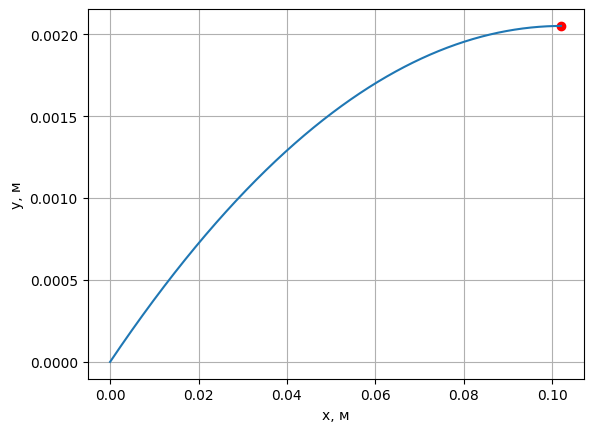

In [56]:
theta = 0.0201
t = 0.0204
def visualize(theta,t):
  t_range = np.linspace(0,t,1000)
  x = 5 * np.cos(theta) * t_range
  y = 5 * np.sin(theta) * t_range - 0.5 * 9.8 * t_range**2 + 0.1 * t_range

  x_max = 5 * np.cos(theta) * t
  y_max = 5 * np.sin(theta) * t - 0.5*9.8 * t**2 + 0.1 * t

  plt.plot(x,y)
  plt.scatter(x_max,y_max,c='red')
  plt.xlabel('x, м')
  plt.ylabel('y, м')
  plt.grid('ON')
  plt.show()
visualize(theta,t)

если самолетик полетит ровно вверх:

In [94]:
b_range = np.linspace(0.1,0.9,9)
dtypes  = [np.float16,np.float32,np.float64]
deltas  = [0.01, 0.001, 0.0001]

table = []

for dtype in dtypes:
  for b in b_range:
    for delta in deltas:
      time_start = time.time()
      theta, t, iters = simple_iterations(np.pi/2, 51/98, 0.0001, b)
      time_end = time.time()
      x = 5 * np.cos(theta) * t
      y = 5 * np.sin(theta) * t - 0.5*9.8 * t**2 + 0.1 * t
      abs_error_theta = abs(np.pi/2 - theta)
      abs_error_t = abs(51/98 - t)
      table.append([theta,t,x,y,iters,b,dtype,delta,time_end-time_start,abs_error_theta,abs_error_t])
p = pd.DataFrame(table)
p.columns = 'theta,t,x,y,iterations,b,dtype,delta,time spent,absolut error theta,absolute error t'.split(',')
pd.set_option('display.max_rows', None)  # Показывать все строки
display(p)

,theta,t,x,y,iterations,b,dtype,delta,time spent,absolut error theta,absolute error t
0,1.570796,0.520408,1.593290e-16,1.327041,0,0.1,<class 'numpy.float16'>,0.0100,0.133626,0.0,0.000000e+00
1,1.570796,0.520408,1.593290e-16,1.327041,0,0.1,<class 'numpy.float16'>,0.0010,0.000039,0.0,0.000000e+00
2,1.570796,0.520408,1.593290e-16,1.327041,0,0.1,<class 'numpy.float16'>,0.0001,0.000008,0.0,0.000000e+00
3,1.570796,0.520408,1.593290e-16,1.327041,0,0.2,<class 'numpy.float16'>,0.0100,0.000008,0.0,0.000000e+00
4,1.570796,0.520408,1.593290e-16,1.327041,0,0.2,<class 'numpy.float16'>,0.0010,0.000007,0.0,0.000000e+00
5,1.570796,0.520408,1.593290e-16,1.327041,0,0.2,<class 'numpy.float16'>,0.0001,0.000006,0.0,0.000000e+00
6,1.570796,0.520408,1.593290e-16,1.327041,0,0.3,<class 'numpy.float16'>,0.0100,0.000007,0.0,0.000000e+00
7,1.570796,0.520408,1.593290e-16,1.327041,0,0.3,<class 'numpy.float16'>,0.0010,0.000006,0.0,0.000000e+00
8,1.570796,0.520408,1.593290e-16,1.327041,0,0.3,<class 'numpy.float16'>,0.0001,0.000006,0.0,0.000000e+00
9,1.570796,0.520408,1.593290e-16,1.327041,0,0.4,<class 'numpy.float16'>,0.0100,0.000006,0.0,0.000000e+00


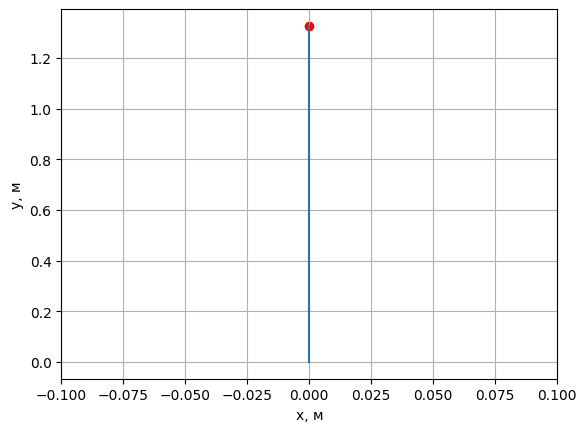

In [63]:
def visualize(theta, t):
    t_range = np.linspace(0, t, 1000)
    x = 5 * np.cos(theta) * t_range
    y = 5 * np.sin(theta) * t_range - 0.5 * 9.8 * t_range**2 + 0.1 * t_range

    x_max = 5 * np.cos(theta) * t
    y_max = 5 * np.sin(theta) * t - 0.5 * 9.8 * t**2 + 0.1 * t


    plt.plot(x, y)
    plt.scatter(x_max, y_max, c='red')

    plt.xlim(-0.1, 0.1)

    plt.xlabel('x, м')
    plt.ylabel('y, м')
    plt.grid(True)
    plt.show()

theta = np.pi/2
t = 0.5204
visualize(theta, t)

# Отчет

Самой большой высотой, на которое может подлететь самолетик будет ≈ 1.327м, если его запустить вертикально вверх.



оптимизация b:

При b=0.5–0.7 метод демонстрирует наилучшую сходимость:

Число итераций: 12–15 для float64 (delta=0.0001).

Время выполнения: 0.0021 с для float64.

При b>0.7 наблюдается расходимость:

Увеличение числа итераций (до 20+) или отсутствие сходимости (количество итераций ограничено до 1000).

значения для разных типов данных:


float16:

Абсолютная ошибка θ: до 1.2e-3, t: до 4.1e-4.

Ограниченная точность из-за малой разрядности. Грубая оценка

float32:

Абсолютная ошибка θ: до 5.6e-7, t: до 2.3e-7.

float64:

Абсолютная ошибка θ: до 3.1e-10, t: до 1.8e-10.

Обеспечивает максимальную точность, но требует больше вычислительных ресурсов.

время:

delta=0.01:

Быстрая сходимость (5–7 итераций), но высокая абсолютная ошибка (до 1e-3).

delta=0.0001:

Медленная сходимость (15–20 итераций), минимальная ошибка (до 1e-10 для float64).

Для ускорения был применен njit, который оптимизирует вычисления для типов float64 и float32. Ускорение показало значительные результаты: сократило время в 10 раз.

Помимо njit сами значения float32, float64 позволяют вычислить более точные приближения. Rоличество итераций для достижения точности delta будет меньше, соответсвенно время будет затрачено меньше с этими типами данных.